# 워크플로우가 충분한 조건

이 절은 모델에게 다음 단계를 고르게 하기 전에 먼저 할 일을 다룹니다.
그 일이 코드가 고르는 흐름, 곧 워크플로우로 충분한지 묻는 일입니다.
질문 다섯에 답하고 점수를 매겨 추천 하나를 냅니다.

**이 노트북에서 할 일**

1. 워크플로우로 충분한지 묻는 진단 질문 다섯과 가중치를 적습니다.
2. 01절에서 만든 사례 셋을 일로 보고 답을 적어 점수와 추천을 냅니다.
3. 단계를 미리 적을 수 있는 일에 모델의 선택을 더한 기록을 01절 함수로 셉니다.
4. 기준값과 답 하나를 바꿔 추천이 어떻게 달라지는지 봅니다.

**준비물** — 이 절은 모델을 부르지 않습니다.
실행하기 전에 진단표를 채워 보는 절이라 이 절에서 정한 답과 손으로 만든 기록을 씁니다.
그래서 OpenAI API 키가 필요 없고 모델 요청은 0번이며 드는 비용도 없습니다.
읽는 자료 파일도 새로 쓰는 파일도 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 1초 안에 끝났습니다.

**기준 버전** — 파이썬에 들어 있는 기능만 써서 설치할 패키지가 없습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~7절을 읽습니다.
진단 질문으로 점수와 추천을 내고 01절 기록을 세는 자리입니다.
8절 기준 근처 사례와 9·10절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

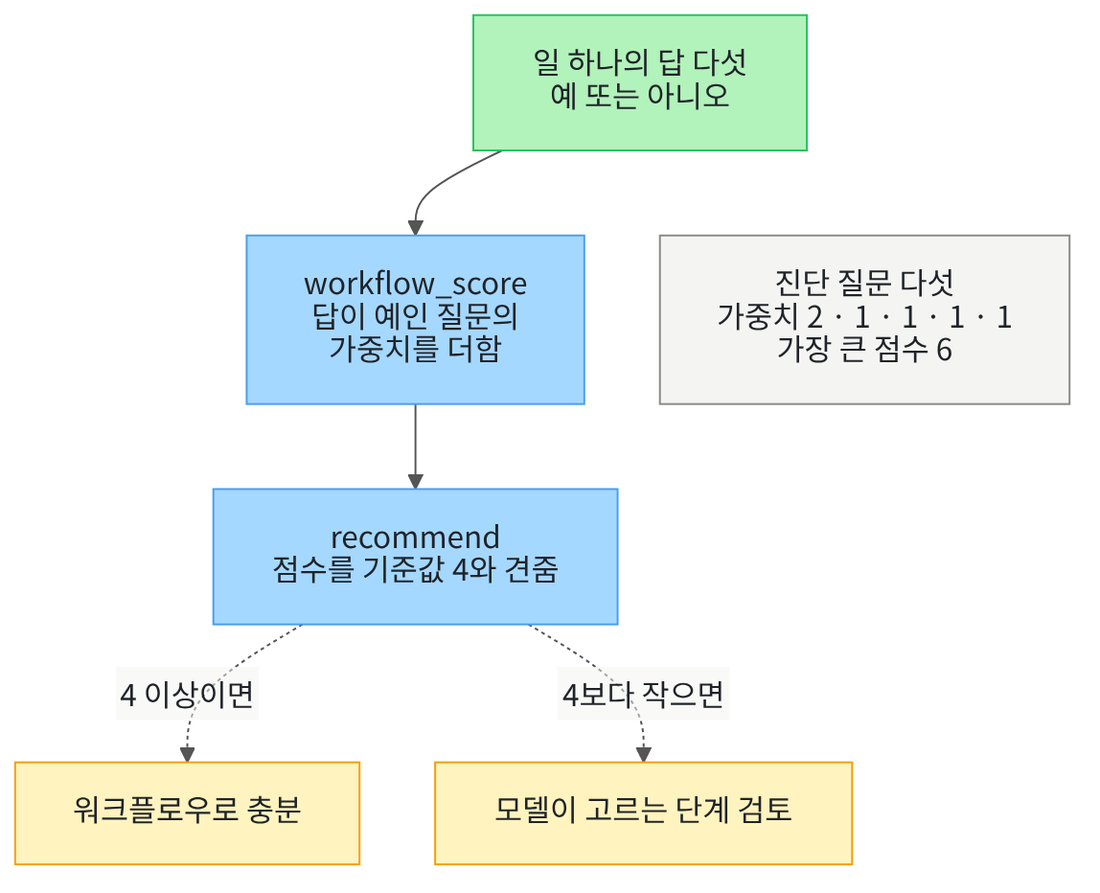

위에서 아래로 읽습니다. 초록 상자는 일 하나에 적은 답 다섯이고, 파란 상자 둘이 점수를 내고 기준값과 견줍니다.
점수가 기준값 이상이면 왼쪽 점선, 작으면 오른쪽 점선을 따라 노란 추천이 나옵니다.
첫 파란 상자 오른쪽의 회색 상자는 질문 다섯과 가중치입니다.

## 1. 준비

이 절은 파이썬에 들어 있는 기능만 씁니다.
첫 셀은 01절에서 배운 함수 셋을 가져오고 파이썬 판을 확인합니다.

앞에서 배운 함수는 `agent_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
가져오는 함수는 기록을 한 줄씩 출력하는 함수, 칸 값을 세는 함수, 구조를 가르는 함수입니다.

In [1]:
# 01절에서 배운 함수 셋을 도구 파일에서 가져오고 파이썬 판을 확인합니다
import sys

from agent_tools import classify, count_steps, print_steps

python_version = sys.version.split()[0]
print("파이썬 판:", python_version)
print("가져온 함수:", "classify", "count_steps", "print_steps")

파이썬 판: 3.12.13
가져온 함수: classify count_steps print_steps


**결과 읽기** — 출력 줄 `파이썬 판: 3.12.13`과 `가져온 함수: classify count_steps print_steps`가 보입니다.
함수 셋은 01절 노트북에서 정의한 함수와 같은 본문입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

## 2. 진단 질문 다섯

진단 질문은 일을 실행하기 전에 그 일이 워크플로우로 충분한지 묻는 질문입니다.
질문마다 가중치를 하나씩 붙이고, 답이 예인 질문의 가중치를 더해 점수를 냅니다.
가중치는 그 질문을 점수에 얼마나 크게 넣을지 정한 수입니다.

첫 질문 「단계를 미리 적을 수 있는가」에만 가중치 2를 주었습니다.
단계를 미리 적을 수 있으면 다음 단계를 코드가 고를 수 있기 때문입니다.
나머지 넷은 가중치가 1이고, 가중치는 모두 이 절에서 정한 값입니다.

넷째 질문의 부작용(side effect)은 결제·삭제·보내기처럼 프로그램 바깥을 바꾸는 동작입니다.
그 앞에서 사람이 확인하는 자리를 승인 지점이라고 부릅니다.
다섯째 질문은 같은 입력에 같은 차례가 다시 나와야 하는지, 곧 반복성을 묻습니다.

In [2]:
# 워크플로우로 충분한지 묻는 진단 질문 다섯과 질문마다 정한 가중치입니다
questions = [
    {"질문": "단계를 미리 적을 수 있는가", "가중치": 2},
    {"질문": "입력 종류를 코드로 가를 수 있는가", "가중치": 1},
    {"질문": "실패했을 때 할 일이 정해져 있는가", "가중치": 1},
    {"질문": "부작용 앞에 사람이 확인할 수 있는가", "가중치": 1},
    {"질문": "같은 입력에 같은 차례가 중요한가", "가중치": 1},
]
print("질문 수:", len(questions))

질문 수: 5


**결과 읽기** — 출력 줄 `질문 수: 5`로 질문 다섯이 목록에 들어갔습니다.
질문 하나는 칸 「질문」과 칸 「가중치」를 가진 딕셔너리입니다.
01절의 기록 한 줄처럼 한국어 키를 썼습니다.

다음 셀은 가중치를 모두 더해 받을 수 있는 가장 큰 점수를 셉니다.

In [3]:
# 가중치를 모두 더해 받을 수 있는 가장 큰 점수를 셉니다
max_score = 0
for question in questions:
    max_score = max_score + question["가중치"]
print("가장 큰 점수:", max_score)

가장 큰 점수: 6


**결과 읽기** — 출력 줄 `가장 큰 점수: 6`이 보입니다.
첫 질문의 2와 나머지 네 질문의 1을 더한 값입니다.
다섯 질문에 모두 예라고 답한 일이 이 점수를 받습니다.

## 3. 일 하나의 답 적기

진단할 첫 일은 01절에서 만든 사례 1, 정해진 환불 절차입니다.
01절에서는 실행한 기록을 읽었고, 이번에는 실행하기 전의 일을 봅니다.
네 단계의 차례를 미리 적을 수 있어 첫 답은 예입니다.
입력은 환불 문의 하나뿐이고, 규정에 맞지 않으면 상담원에게 넘긴다고 정해 둘 수 있습니다.
환불 요청 등록 앞에는 사람 확인을 둘 수 있고, 같은 주문은 같은 차례로 처리해야 합니다.

일 하나는 칸 「이름」과 칸 「답」을 가진 딕셔너리입니다.
답은 질문 차례대로 `예`나 `아니오`를 적은 목록이고, 이 절에서 정한 답입니다.

In [4]:
# 01절 사례 1 · 정해진 환불 절차를 일로 보고 질문 다섯에 답합니다
refund_work = {
    "이름": "정해진 환불 절차",
    "답": ["예", "예", "예", "예", "예"],
}
print("일:", refund_work["이름"])
print("답 수:", len(refund_work["답"]))

일: 정해진 환불 절차
답 수: 5


**결과 읽기** — 출력 줄 `일: 정해진 환불 절차`와 `답 수: 5`가 보입니다.
답이 질문 수와 같은 다섯 개라 질문과 답을 같은 번호로 짝지을 수 있습니다.

다음 셀은 질문과 답을 한 줄씩 나란히 출력하는 함수입니다.
번호 `i`로 질문 목록과 답 목록을 함께 돕니다.
01절 함수 `print_steps`처럼 라벨 줄을 먼저 출력합니다.

In [5]:
# 질문마다 번호·질문·가중치·답을 한 줄씩 출력합니다
def print_answers(questions, answers):
    print("번호 | 질문 | 가중치 | 답")
    for i in range(len(questions)):
        question = questions[i]
        print(i, "|", question["질문"], "|", question["가중치"], "|", answers[i])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_answers`는 질문 목록과 답 목록을 받아 같은 번호끼리 한 줄에 출력합니다.
두 목록의 길이가 같아야 합니다.

다음 셀은 환불 절차의 답을 읽습니다.

In [6]:
# 정해진 환불 절차의 답을 질문과 나란히 읽습니다
print_answers(questions, refund_work["답"])

번호 | 질문 | 가중치 | 답
0 | 단계를 미리 적을 수 있는가 | 2 | 예
1 | 입력 종류를 코드로 가를 수 있는가 | 1 | 예
2 | 실패했을 때 할 일이 정해져 있는가 | 1 | 예
3 | 부작용 앞에 사람이 확인할 수 있는가 | 1 | 예
4 | 같은 입력에 같은 차례가 중요한가 | 1 | 예


**결과 읽기** — 라벨 줄 `번호 | 질문 | 가중치 | 답` 아래 다섯 줄이 환불 절차의 답입니다.
출력 줄 `0 | 단계를 미리 적을 수 있는가 | 2 | 예`부터 다섯 줄 모두 답이 예입니다.

## 4. 워크플로우 점수

워크플로우 점수는 답이 예인 진단 질문의 가중치를 모두 더한 값입니다.
이 절은 점수가 클수록 코드가 고르는 흐름으로 충분한 쪽으로 봅니다.
다음 셀은 질문 목록과 답 목록을 받아 이 점수를 내놓는 함수입니다.
번호 `i`로 두 목록을 함께 돌고, 답이 `예`일 때만 가중치를 더합니다.

In [7]:
# 답이 예인 질문의 가중치만 더해 워크플로우 점수를 냅니다
def workflow_score(questions, answers):
    score = 0
    for i in range(len(questions)):
        if answers[i] == "예":
            score = score + questions[i]["가중치"]
    return score

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `workflow_score`는 점수 하나를 내놓습니다.
모든 답이 예이면 2절의 가장 큰 점수와 같고, 모두 아니오이면 0입니다.
6절에서 이 두 경우를 손으로 확인합니다.

다음 셀은 환불 절차의 점수를 셉니다.

In [8]:
# 정해진 환불 절차의 워크플로우 점수를 셉니다
refund_score = workflow_score(questions, refund_work["답"])
print("정해진 환불 절차 점수:", refund_score)

정해진 환불 절차 점수: 6


**결과 읽기** — 출력 줄 `정해진 환불 절차 점수: 6`으로 가장 큰 점수를 받았습니다.
다섯 질문에 모두 예라고 답했기 때문입니다.

## 5. 기준값과 추천

점수를 기준값과 견줘 추천 하나를 냅니다.
기준값은 Ch 13 03절에서처럼 갈래를 가르려고 코드에 적어 둔 값입니다.
점수가 기준값 이상이면 「워크플로우로 충분」, 작으면 「모델이 고르는 단계 검토」를 냅니다.
뒤의 추천은 모델에게 다음 단계를 고르게 할지 따져 볼 일이라는 뜻입니다.

이 추천은 01절의 「에이전트 후보」와 다른 말입니다.
01절은 실행한 기록을 갈랐고, 이 절은 실행하기 전의 일을 진단합니다.

In [9]:
# 점수가 기준값 이상이면 워크플로우로 충분, 아니면 모델이 고르는 단계 검토를 냅니다
def recommend(score, standard):
    if score >= standard:
        return "워크플로우로 충분"
    return "모델이 고르는 단계 검토"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `recommend`는 점수와 기준값을 받아 추천 이름 하나를 내놓습니다.
점수가 기준값과 같을 때도 「워크플로우로 충분」입니다.

다음 셀은 기준값을 4로 정하고 환불 절차의 추천을 봅니다.
기준값 4는 흐름을 보여 주려고 이 절에서 정한 값입니다.
라이브러리 기본값도 아니고 무엇을 재서 얻은 값도 아닙니다.

In [10]:
# 기준값을 4로 정하고 정해진 환불 절차의 추천을 봅니다
standard_score = 4
refund_advice = recommend(refund_score, standard_score)
print("기준값:", standard_score)
print("정해진 환불 절차 추천:", refund_advice)

기준값: 4
정해진 환불 절차 추천: 워크플로우로 충분


**결과 읽기** — 출력 줄 `기준값: 4`와 `정해진 환불 절차 추천: 워크플로우로 충분`이 보입니다.
점수 6이 기준값 4 이상이라 워크플로우로 충분하다는 추천이 나왔습니다.

## 6. 단계를 미리 적기 어려운 일

다음 일은 01절 사례 4, 낯선 장애 원인 조사입니다.
어느 설정 파일을 볼지는 오류 기록을 읽어 봐야 알아서 첫 답은 아니오입니다.
오류 모양이 처음 보는 것이라 입력 종류를 코드로 가를 수 없습니다.
조사가 막히면 무엇을 할지도 정해 두지 못했습니다.
조사 뒤 설정을 고치는 단계까지 이 일로 보면, 그 앞에는 사람 확인을 둘 수 있고 장애마다 차례는 달라도 됩니다.

In [11]:
# 01절 사례 4 · 낯선 장애 원인 조사의 답을 적고 질문과 나란히 읽습니다
incident_work = {
    "이름": "낯선 장애 원인 조사",
    "답": ["아니오", "아니오", "아니오", "예", "아니오"],
}
print_answers(questions, incident_work["답"])

번호 | 질문 | 가중치 | 답
0 | 단계를 미리 적을 수 있는가 | 2 | 아니오
1 | 입력 종류를 코드로 가를 수 있는가 | 1 | 아니오
2 | 실패했을 때 할 일이 정해져 있는가 | 1 | 아니오
3 | 부작용 앞에 사람이 확인할 수 있는가 | 1 | 예
4 | 같은 입력에 같은 차례가 중요한가 | 1 | 아니오


**결과 읽기** — 라벨 줄 아래 다섯 줄 가운데 출력 줄 `3 | 부작용 앞에 사람이 확인할 수 있는가 | 1 | 예`만 답이 예입니다.
나머지 네 줄은 답이 아니오입니다.

다음 셀은 이 일의 점수와 기준값 4에서의 추천을 봅니다.

In [12]:
# 낯선 장애 원인 조사의 점수와 기준값 4에서의 추천을 봅니다
incident_score = workflow_score(questions, incident_work["답"])
incident_advice = recommend(incident_score, standard_score)
print("낯선 장애 원인 조사 점수:", incident_score)
print("낯선 장애 원인 조사 추천:", incident_advice)

낯선 장애 원인 조사 점수: 1
낯선 장애 원인 조사 추천: 모델이 고르는 단계 검토


**결과 읽기** — 출력 줄 `낯선 장애 원인 조사 점수: 1`과 `낯선 장애 원인 조사 추천: 모델이 고르는 단계 검토`가 보입니다.
점수 1은 넷째 질문의 가중치 하나뿐입니다.
사람 확인을 둘 수 있어도 단계를 미리 적을 수 없는 일은 점수가 낮습니다.

다음 셀은 손으로 적은 작은 답 둘로 두 함수의 동작을 확인합니다.
모든 답이 예인 목록과 모든 답이 아니오인 목록입니다.
조건이 참이 아니면 셀을 멈추는 `assert` 줄로 확인합니다.

In [13]:
# 손으로 적은 작은 답 둘로 점수 함수와 추천 함수의 동작을 확인합니다
all_yes = ["예", "예", "예", "예", "예"]
all_no = ["아니오", "아니오", "아니오", "아니오", "아니오"]
assert workflow_score(questions, all_yes) == 6
assert workflow_score(questions, all_no) == 0
assert recommend(4, 4) == "워크플로우로 충분"
assert recommend(3, 4) == "모델이 고르는 단계 검토"
print("손 확인 통과:", workflow_score(questions, all_yes), workflow_score(questions, all_no))

손 확인 통과: 6 0


**결과 읽기** — 출력 줄 `손 확인 통과: 6 0`으로 네 `assert` 줄이 모두 지나갔습니다.
모든 답이 예이면 가장 큰 점수 6, 모두 아니오이면 0입니다.
점수와 기준값이 같은 4일 때 추천이 워크플로우로 충분인 것도 확인했습니다.

## 7. 01절 기록으로 보는 필요 없는 자율성

환불 절차는 점수 6으로 워크플로우로 충분하다는 추천을 받았습니다.
그런데 이 일에서 모델이 다음 단계를 고르게 하면 기록이 어떻게 달라질까요?
다음 셀은 01절에서 만든 환불 절차 기록을 다시 적습니다.
네 줄 모두 칸 「고른 쪽」이 `코드`입니다.

In [14]:
# 01절 사례 1의 실행 기록입니다: 네 단계의 차례를 모두 코드가 고릅니다
refund_steps = [
    {"단계": "주문 조회", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "환불 규정 확인", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "환불 요청 등록", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "안내 문장 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
]
print("코드가 고른 기록 줄 수:", len(refund_steps))

코드가 고른 기록 줄 수: 4


**결과 읽기** — 출력 줄 `코드가 고른 기록 줄 수: 4`로 01절 사례 1과 같은 네 줄입니다.

다음 셀은 같은 일을 모델이 고르게 한 기록입니다.
이 절에서 손으로 만든 기록이고, 모델을 부르지 않았습니다.
코드가 단계마다 모델에게 다음 단계를 묻고, 모델이 고른 단계를 실행한다고 정했습니다.
모델은 코드에 적어 둔 것과 같은 차례를 골랐다고 적었습니다.

In [15]:
# 같은 일을 모델이 고르게 한 기록입니다: 다음 단계 고르기 두 줄이 더해집니다
model_refund_steps = [
    {"단계": "주문 조회", "한 쪽": "도구", "고른 쪽": "코드"},
    {"단계": "다음 단계 고르기", "한 쪽": "모델", "고른 쪽": "코드"},
    {"단계": "환불 규정 확인", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "다음 단계 고르기", "한 쪽": "모델", "고른 쪽": "코드"},
    {"단계": "환불 요청 등록", "한 쪽": "도구", "고른 쪽": "모델"},
    {"단계": "안내 문장 쓰기", "한 쪽": "모델", "고른 쪽": "코드"},
]
print_steps(model_refund_steps)

번호 | 단계 | 한 쪽 | 고른 쪽
0 | 주문 조회 | 도구 | 코드
1 | 다음 단계 고르기 | 모델 | 코드
2 | 환불 규정 확인 | 도구 | 모델
3 | 다음 단계 고르기 | 모델 | 코드
4 | 환불 요청 등록 | 도구 | 모델
5 | 안내 문장 쓰기 | 모델 | 코드


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽` 아래 여섯 줄이 모델이 고르게 한 기록입니다.
출력 줄 `1 | 다음 단계 고르기 | 모델 | 코드`와 `3 | 다음 단계 고르기 | 모델 | 코드`가 새로 더해진 줄입니다.
그 바로 뒤 두 줄은 칸 「고른 쪽」이 `모델`입니다.

다음 셀은 두 기록을 01절 함수 `count_steps`와 `classify`로 세어 한 표로 봅니다.
이 절의 기록에서 모델이 한 단계 하나는 모델 요청 한 번으로 셉니다.

In [16]:
# 두 기록의 줄 수·모델이 한 단계·모델이 고른 단계·구조를 한 표로 봅니다
records = [
    {"이름": "코드가 고른 기록", "기록": refund_steps},
    {"이름": "모델이 고른 기록", "기록": model_refund_steps},
]
print("기록 | 줄 수 | 모델이 한 단계 | 모델이 고른 단계 | 구조")
for record in records:
    steps = record["기록"]
    model_work = count_steps(steps, "한 쪽", "모델")
    chosen = count_steps(steps, "고른 쪽", "모델")
    print(record["이름"], "|", len(steps), "|", model_work, "|", chosen, "|", classify(steps))

기록 | 줄 수 | 모델이 한 단계 | 모델이 고른 단계 | 구조
코드가 고른 기록 | 4 | 1 | 0 | 워크플로우
모델이 고른 기록 | 6 | 3 | 2 | 에이전트 후보


**결과 읽기** — 라벨 줄 아래 두 줄을 견줍니다.
출력 줄 `코드가 고른 기록 | 4 | 1 | 0 | 워크플로우`와 `모델이 고른 기록 | 6 | 3 | 2 | 에이전트 후보`가 보입니다.
모델에게 고르게 하자 모델이 한 단계가 하나에서 셋으로 늘었습니다.
늘어난 두 단계는 모두 다음 단계를 고르는 일이었습니다.

두 기록에서 도구가 한 일은 같았을까요?
다음 셀은 기록에서 칸 「한 쪽」이 `도구`인 줄의 단계 이름만 차례대로 모으는 함수입니다.
빈 목록을 만들고 `append`로 하나씩 채웁니다.

In [17]:
# 기록에서 도구가 한 단계의 이름만 차례대로 모읍니다
def tool_names(steps):
    names = []
    for step in steps:
        if step["한 쪽"] == "도구":
            names.append(step["단계"])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `tool_names`는 기록 하나를 받아 도구가 한 단계 이름의 목록을 내놓습니다.
목록 안의 차례는 기록의 차례와 같습니다.

다음 셀은 두 기록의 도구 차례를 모아 견줍니다.
목록끼리 `==`로 견주면 길이와 차례, 값이 모두 같을 때만 `True`가 나옵니다.

In [18]:
# 두 기록에서 도구가 지난 차례를 모아 같은지 봅니다
code_tools = tool_names(refund_steps)
model_tools = tool_names(model_refund_steps)
print("코드가 고른 기록의 도구 차례:", code_tools)
print("모델이 고른 기록의 도구 차례:", model_tools)
print("두 차례가 같은가:", code_tools == model_tools)

코드가 고른 기록의 도구 차례: ['주문 조회', '환불 규정 확인', '환불 요청 등록']
모델이 고른 기록의 도구 차례: ['주문 조회', '환불 규정 확인', '환불 요청 등록']
두 차례가 같은가: True


**결과 읽기** — 출력 줄 `두 차례가 같은가: True`로 도구 차례가 같았습니다.
두 기록 모두 주문 조회, 환불 규정 확인, 환불 요청 등록을 차례로 지났습니다.
모델이 코드와 같은 차례를 고른다면 모델 요청만 둘 늘고 도구가 한 일은 그대로입니다.
이 기록은 모델이 그렇게 골랐다고 정해 적은 사례입니다.

## 8. 기준 근처에 있는 일

셋째 일은 01절 사례 5, 문의 종류 가르기입니다.
이 사례는 점수가 기준값 근처에 오도록 실행 전에 정해 둔 사례입니다.
9절에서 기준값을 바꿀 때 추천이 달라지는 장면을 보이려는 것입니다.

종류마다 다음 단계를 01절 함수 `pick_next_step`처럼 코드에 적어 둘 수 있어 첫 답은 예입니다.
손님 글은 모델이 읽고 종류 이름을 써야 가를 수 있어 둘째 답은 아니오입니다.
준비에 없는 종류는 상담원에게 보낸다고 정해 두어 셋째 답은 예입니다.
모델이 쓴 답을 손님에게 바로 보내 넷째 답은 아니오, 같은 종류는 같은 차례라 다섯째 답은 예입니다.

In [19]:
# 01절 사례 5 · 문의 종류 가르기의 답을 적고 질문과 나란히 읽습니다
routing_work = {
    "이름": "문의 종류 가르기",
    "답": ["예", "아니오", "예", "아니오", "예"],
}
print_answers(questions, routing_work["답"])

번호 | 질문 | 가중치 | 답
0 | 단계를 미리 적을 수 있는가 | 2 | 예
1 | 입력 종류를 코드로 가를 수 있는가 | 1 | 아니오
2 | 실패했을 때 할 일이 정해져 있는가 | 1 | 예
3 | 부작용 앞에 사람이 확인할 수 있는가 | 1 | 아니오
4 | 같은 입력에 같은 차례가 중요한가 | 1 | 예


**결과 읽기** — 라벨 줄 아래 다섯 줄에서 답이 예인 줄은 셋입니다.
출력 줄 `0 | 단계를 미리 적을 수 있는가 | 2 | 예`가 그 가운데 하나입니다.
가중치 2인 첫 질문이 예라 점수가 크게 오릅니다.

다음 셀은 이 일의 점수와 기준값 4에서의 추천을 봅니다.

In [20]:
# 문의 종류 가르기의 점수와 기준값 4에서의 추천을 봅니다
routing_score = workflow_score(questions, routing_work["답"])
routing_advice = recommend(routing_score, standard_score)
print("문의 종류 가르기 점수:", routing_score)
print("문의 종류 가르기 추천:", routing_advice)

문의 종류 가르기 점수: 4
문의 종류 가르기 추천: 워크플로우로 충분


**결과 읽기** — 출력 줄 `문의 종류 가르기 점수: 4`와 `문의 종류 가르기 추천: 워크플로우로 충분`이 보입니다.
점수 4가 기준값 4와 같아 워크플로우로 충분이 나왔습니다.
기준값이 조금만 올라가도 추천이 바뀔 자리입니다.

## 9. 값 바꿔 보기 · 기준값

바꿀 값은 기준값 하나입니다.
3, 4, 5 세 값으로 바꿔 가며 세 일의 추천을 봅니다.
답과 가중치는 그대로 둡니다.

실행 전에 예상해 봅니다.
환불 절차는 점수 6이라 세 기준값에서 모두 워크플로우로 충분일 것입니다.
장애 원인 조사는 점수 1이라 세 기준값에서 모두 검토일 것입니다.
문의 종류 가르기는 기준값 5에서만 추천이 바뀔 것입니다.

In [21]:
# 바꿀 값 1: 기준값을 3·4·5로 바꿔 가며 세 일의 추천을 봅니다
works = [refund_work, incident_work, routing_work]
standard_list = [3, 4, 5]
print("기준값 | 일 | 점수 | 추천")
for standard_value in standard_list:
    for work in works:
        score = workflow_score(questions, work["답"])
        print(standard_value, "|", work["이름"], "|", score, "|", recommend(score, standard_value))

기준값 | 일 | 점수 | 추천
3 | 정해진 환불 절차 | 6 | 워크플로우로 충분
3 | 낯선 장애 원인 조사 | 1 | 모델이 고르는 단계 검토
3 | 문의 종류 가르기 | 4 | 워크플로우로 충분
4 | 정해진 환불 절차 | 6 | 워크플로우로 충분
4 | 낯선 장애 원인 조사 | 1 | 모델이 고르는 단계 검토
4 | 문의 종류 가르기 | 4 | 워크플로우로 충분
5 | 정해진 환불 절차 | 6 | 워크플로우로 충분
5 | 낯선 장애 원인 조사 | 1 | 모델이 고르는 단계 검토
5 | 문의 종류 가르기 | 4 | 모델이 고르는 단계 검토


**결과 읽기** — 라벨 줄 `기준값 | 일 | 점수 | 추천` 아래 아홉 줄이 세 기준값과 세 일의 짝입니다.
출력 줄 `4 | 문의 종류 가르기 | 4 | 워크플로우로 충분`과 `5 | 문의 종류 가르기 | 4 | 모델이 고르는 단계 검토`를 견줍니다.
문의 종류 가르기만 기준값 5에서 추천이 바뀌었습니다.
환불 절차와 장애 원인 조사는 세 기준값에서 추천이 같아 예상과 맞았습니다.

기준값이 추천을 바꾸는 것은 점수가 기준값 근처인 일뿐이었습니다.
그런 일은 점수만 보고 정하지 않고 팀이 함께 살펴봅니다.

## 10. 값 바꿔 보기 · 가중치 2인 답 하나

이번에는 기준값을 두고 답 하나만 바꿉니다.
문의 종류 가르기의 첫 답 「단계를 미리 적을 수 있는가」를 아니오로 바꿉니다.
문의 종류가 자꾸 새로 생겨 종류마다 차례를 적어 둘 수 없게 된 경우입니다.
목록 뒤에 `[1:]`을 붙이면 둘째 값부터 끝까지 담은 새 목록이 됩니다.
Ch 16 01절에서 쓴 모양입니다.

실행 전에 예상해 봅니다.
가중치 2가 빠져 점수는 4에서 2로 내려갈 것입니다.
기준값 3·4·5 어디서나 모델이 고르는 단계 검토가 나올 것입니다.

In [22]:
# 바꿀 값 2: 문의 종류 가르기의 첫 답만 아니오로 바꾼 새 답 목록을 만듭니다
routing_answers = routing_work["답"]
changed_answers = ["아니오"] + routing_answers[1:]
changed_score = workflow_score(questions, changed_answers)
print("바꾼 답의 점수:", changed_score)
for standard_value in standard_list:
    print("기준값", standard_value, "→", recommend(changed_score, standard_value))
print("원래 답의 점수:", workflow_score(questions, routing_answers))

바꾼 답의 점수: 2
기준값 3 → 모델이 고르는 단계 검토
기준값 4 → 모델이 고르는 단계 검토
기준값 5 → 모델이 고르는 단계 검토
원래 답의 점수: 4


**결과 읽기** — 출력 줄 `바꾼 답의 점수: 2`와 `원래 답의 점수: 4`가 보입니다.
출력 줄 `기준값 3 → 모델이 고르는 단계 검토`처럼 세 기준값 모두 검토가 나왔습니다.
9절에서 기준값을 바꿨을 때는 기준값 5에서만 추천이 바뀌었습니다.
첫 답 하나를 바꾸자 세 기준값 모두에서 바뀌어 예상과 맞았습니다.
원래 답 목록은 바뀌지 않았습니다.

## 정리

1. 진단 질문 다섯에 답하고, 답이 예인 질문의 가중치를 더한 점수를 기준값과 견줘 추천을 냈습니다.
2. 단계를 미리 적을 수 있는 환불 절차는 점수 6이었습니다. 모델이 고르게 한 기록은 도구 차례는 그대로였고 모델이 한 단계가 둘 늘었습니다.
3. 기준값을 바꾸면 기준 근처의 일만 추천이 바뀌었고, 첫 답 하나를 바꾸면 세 기준값 모두에서 바뀌었습니다.

03절에서는 모델이 고르는 흐름의 모델·도구·반복과 그 반복을 멈추는 조건을 다룹니다.